In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

plt.rcParams["animation.html"] = "jshtml"

In [2]:
def ballistic_deposition(length, width, time):
    """
    Simulates (2+1)D Ballistic Deposition on a 2D lattice

    Args:
        length (int): number of lattice points in one dimension
        width (int): number of lattice points in one dimension
        time (int): number of steps to simulate ballistic deposition for

    Returns:
        particles (array of 3-tuples): positions and heights of particles added to surface at each time step
    """

    heights = np.zeros((length+2, width+2))
    particles = np.zeros((time, 3))

    x_vals = np.random.randint(1, length+1, time)
    y_vals = np.random.randint(1, width+1, time)

    for t in range(time):
        h = max_adjacent(heights, (x_vals[t], y_vals[t]))
        heights[x_vals[t], y_vals[t]] = h
        particles[t] = x_vals[t], y_vals[t], h

    return particles

def max_adjacent(heights, position):
    """
    For a given position on the lattice and the array of heights on the lattice, checks and returns
    the largest height among all adjacent neighbors and the current position + 1

    Args:
        heights (2D array of ints): contains the height of the surface at every position
        position (int, int): 2-tuple of ints that determine a position on the lattice

    Returns:
        (int) maximum height among the current position's height + 1 and its adjacent neighbors
    """
    x = position[0]
    y = position[1]

    return max(heights[x-1, y+1], heights[x, y+1], heights[x+1, y+1],
               heights[x-1, y], heights[x, y] + 1, heights[x+1, y],
               heights[x-1, y-1], heights[x, y-1], heights[x+1, y-1])

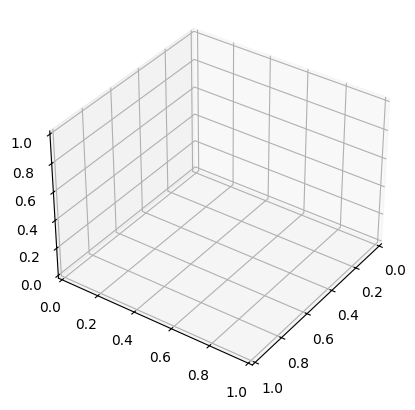

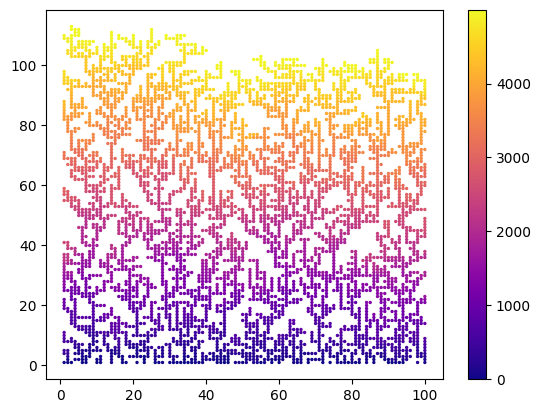

In [3]:
LENGTH = 100
WIDTH = 1
TIME = 5000

parts = ballistic_deposition(LENGTH, WIDTH, TIME)
plt.figure()
ax = plt.axes(projection='3d')
# ax.scatter(parts[:, 0], parts[:, 1], parts[:, 2], c=range(TIME), cmap='plasma', edgecolors='black', s=10)
# ax.plot_trisurf(parts[:, 0], parts[:, 1], parts[:, 2], cmap='plasma', edgecolors='none')
# plt.colorbar()
ax.view_init(35, 35)
plt.show()

plt.scatter(parts[:, 0], parts[:, 2], c=range(TIME), cmap='plasma', s=2)
plt.colorbar()
plt.show()

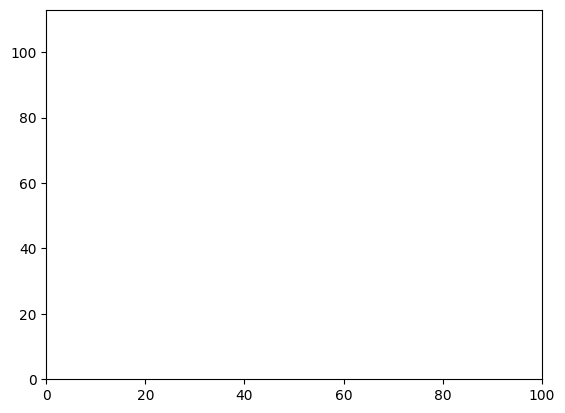

In [4]:
# fig = plt.figure()
# ax = plt.axes(projection='3d')
fig, ax = plt.subplots()
# scat = ax.scatter(parts[0, 0], parts[0, 1], parts[0, 2], edgecolors='black')
scat = ax.scatter(parts[0, 0], parts[0, 2], edgecolors='black', s=2)
ax.set(xlim=[0, LENGTH], ylim = [0, np.max(parts[:, 2])])

def update(frame):
    surface_x = parts[:100*frame, 0]
    surface_y = parts[:100*frame, 1]
    surface_z = parts[:100*frame, 2]

    # Update scatter plot
    # data = np.stack([surface_x, surface_y, surface_z], axis=1)
    data = np.stack([surface_x, surface_z], axis = 1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=TIME//100, interval=45)
ani